# Visualisation 

# 1. Imports

In [1]:
import numpy as np
import pandas as pd
import tifffile as tiff
from astropy.io import fits
import h5py
import json

from utils.naming import *
from pathlib import Path
from matplotlib import colormaps

import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch
from matplotlib.colors import SymLogNorm, LogNorm
from matplotlib.patches import Circle
import imageio.v2 as imageio

# --- Data locations ----------------------------------------------------------
GHOST = Path("/home/aosimul/noah/data/ghost_images")
RESULTS = Path("/home/aosimul/noah/src/pipeline_pre_ADI/results")
SAVE_CUBES = Path("/home/aosimul/noah/notebooks/results/fits_cubes")

RAW_TIF_DIR = GHOST / "phase_screens_SLM/10_10"  # raw .tif frames
RAW_BENCH_DIR = GHOST / "phase_screens_SLM/10_13"  # raw .tif frames
RUNS_BENCH = GHOST / "bench"  # batches to characterise the bench and set up noise
LONG_RUN_FOCUS = (
    GHOST / "long_7ro_20ws_focus"
)  # stacked _1-4 / _5-8, DIT = 2.814 ms with focus

DIT_LONG = 2.814e-3

# saving up to a desired amount of frames:
stop = 50

# 2. Function library

Taken from the temporal correlation notebook

In [ ]:
def wiener_khinchin_acf(stack, subtract="median"):
    """Circular temporal ACF per pixel via the Wiener-Khinchin theorem (IFFT of the PSD).

    Normalised so that lag 0 equals 1. Returns an array shaped like `stack`."""
    x = np.asarray(stack, dtype=np.float32)
    if subtract == "median":
        x = x - np.median(x, axis=0, keepdims=True)
    elif subtract == "mean":
        x = x - np.mean(x, axis=0, keepdims=True)
    P = np.abs(np.fft.rfft(x, axis=0)) ** 2
    acf = np.fft.irfft(P, n=x.shape[0], axis=0)
    zero_lag = acf[0:1]
    return np.divide(acf, zero_lag, out=np.full_like(acf, np.nan), where=zero_lag > 0)


def save_raw_and_acf(
    input_folder, output_folder, algo, ro=None, ws=None, key=None, count=None, stop=None
):
    """Load a np cube and save into fits file the raw data, the median-subtracted data, and the ACF."""
    run = dict(ro=ro, ws=ws, key=key, count=count)
    stack = load_stack(input_folder, algo=algo, **run)
    stack_med_sub = stack - np.median(stack, axis=0)
    acf = wiener_khinchin_acf(stack)
    name = "_".join(
        p for p in (algo, run_name(**run)) if p
    )  # e.g. 'pred_7ro_20ws_1key_1-4'
    fits.writeto(
        (output_folder / f"cube_{name}_raw.fits"), stack[:stop], overwrite=True
    )
    fits.writeto(
        output_folder / f"cube_{name}_med_sub.fits",
        stack_med_sub[:stop],
        overwrite=True,
    )
    fits.writeto(output_folder / f"cube_{name}_acf.fits", acf[:stop], overwrite=True)

# 3. Save Fits cubes

## 3.1 Phase Screens

In [ ]:
mat_paths = {
    1: "SLM_phase_screens_0.70ro_20.04ws.mat",
    24: "now/SLM_phase_screens_0.70ro_20.04ws_24key.mat",
    32: "now/SLM_phase_screens_0.70ro_20.04ws_32key.mat",
}
for key, mat_path in mat_paths.items():
    with h5py.File(GHOST / f"phase_screens_send/{mat_path}", "r") as f:
        print("Original shape:", f["turb"].shape)
        stack = f["turb"][:stop, :, :]
        name = f"phase_screens_{key}key"
        fits.writeto((SAVE_CUBES / f"cube_{name}_raw.fits"), stack, overwrite=True)

## 3.2 Pre-processed data and ACF

In [ ]:
stop = 50
for ds in ["int", "pred"]:
    for key in [1, 24, 32]:
        save_raw_and_acf(
            input_folder=LONG_RUN_FOCUS,
            output_folder=SAVE_CUBES,
            algo=ds,
            ro=7,
            ws=20,
            key=key,
            count="1-4",
            stop=stop,
        )

## 3.3 Bench data

In [ ]:
# Open Loop
for key in [1, 24, 32]:
    save_raw_and_acf(
        input_folder=RUNS_BENCH,
        output_folder=SAVE_CUBES,
        algo="OL",
        ro=7,
        ws=20,
        key=key,
        count="1-4",
        stop=stop,
    )

# Closed Loop
save_raw_and_acf(
    input_folder=RUNS_BENCH, output_folder=SAVE_CUBES, algo="CL", count="1-4", stop=stop
)

## 3.4 PCA Residuals and Fake Planet Experiment

In [ ]:
data = fits.getdata("image.fits", ext=1)

# 4. Make Fits films

In [3]:
def fits_to_video(
    fits_path, out_path, fps=10, cmap="inferno", pmin=1, pmax=99.5, scale=1, hdu=0
):
    cube = fits.getdata(fits_path, ext=hdu).astype(float)  # (n_frames, y, x)

    # one global intensity range, so brightness doesn't flicker between frames
    vmin, vmax = np.percentile(cube, [pmin, pmax])
    norm = np.clip((cube - vmin) / (vmax - vmin), 0, 1)

    lut = colormaps[cmap]
    with imageio.get_writer(
        out_path, fps=fps, codec="libx264", quality=8, macro_block_size=1
    ) as writer:
        for frame in norm:
            rgb = (lut(frame)[..., :3] * 255).astype(np.uint8)
            if scale > 1:  # integer upscaling
                rgb = rgb.repeat(scale, axis=0).repeat(scale, axis=1)
            writer.append_data(rgb)


for fits_path in sorted(list(SAVE_CUBES.glob("*.fits"))):
    fits_to_video(
        fits_path,
        SAVE_CUBES / f"{fits_path.name.replace('.fits','')}.mp4",
        cmap="coolwarm",
        fps=10,
        scale=4,
    )

# 5. Applefy residual frames and movies

Residuals written by the applefy contrast pipeline for one DIT. Each `residual_ID_XXXX.fits` is a single 91x91 frame: `0000` is the planet-free residual, `0001a` ... `0009f` are the fake-planet injections (separation index, azimuth letter). The separation and position of each injection are read from `configs_cgrid/exp_ID_XXXX.json`.

Residuals are shown in ADU as written by the pipeline. Colour scaling is symmetric-log: linear within one sigma of the noise, logarithmic beyond, so faint signal is stretched without losing the sign.

* Side by side: cADI residual vs PCA residual for frame `0000`, each with its own colour range and colorbar, labelled in the bottom-left corner.
* Movies: every residual frame of the chosen PCA reduction, in injection order, with the separation in FWHM in the corner label and a dashed circle (1 FWHM radius) around the injected planet. A second movie shows the residual minus the planet-free frame, i.e. the planet signal alone.

In [ ]:
# --- Applefy residual locations -----------------------------------------------
APPLEFY_RUN = Path(
    "/home/aosimul/noah/src/pipeline_ADI/results/fake_planets/30_deg_sat_speckles"
    "/int_7ro_20ws_1key_1-4_DIT_2.81e-02s"
)
N_PCA = 30
SAVE_APPLEFY = Path("/home/aosimul/noah/notebooks/results/applefy_movies")
SAVE_APPLEFY.mkdir(parents=True, exist_ok=True)

RESIDUALS = APPLEFY_RUN / "residuals"
CONFIGS = APPLEFY_RUN / "configs_cgrid"  # exp_ID_XXXX.json, one per residual frame
CADI_DIR = RESIDUALS / "cADI"
PCA_DIR = RESIDUALS / f"_PCA_{N_PCA:03d}_components"
SEP_STEP_FWHM = 1.0  # fake_planets.separation in config_files/ghost.yaml

CMAP = "inferno"
LABEL_BOX = dict(
    boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.8
)


def load_residual(folder, frame_id="0000"):
    """Single residual frame (2-D array, ADU) from an applefy residual folder."""
    return fits.getdata(folder / f"residual_ID_{frame_id}.fits", ext=0).astype(float)


def load_residual_cube(folder):
    """All residual frames of a folder stacked into (n_frames, y, x) in ADU, in
    file-name order (0000, 0001a, 0001b, ..., 0009f). Also returns the frame IDs."""
    paths = sorted(folder.glob("residual_ID_*.fits"))
    ids = [pth.stem.replace("residual_ID_", "") for pth in paths]
    cube = np.stack([fits.getdata(pth, ext=0).astype(float) for pth in paths])
    return cube, ids


def load_planet_configs(config_dir, frame_ids, sep_step_fwhm=SEP_STEP_FWHM):
    """Per frame: separation in FWHM and planet (x, y) pixel position, from the applefy
    experiment configs. Applefy places planets at multiples of `fwhm * sep_step_fwhm` pixels,
    so the smallest separation fixes the FWHM in pixels. Planet-free frames get NaN."""
    sep_px, xy = {}, {}
    for fid in frame_ids:
        with open(config_dir / f"exp_ID_{fid}.json") as f:
            cfg = json.load(f)
        sep_px[fid] = cfg.get("separation", np.nan)
        xy[fid] = (
            tuple(cfg["planet_position"][:2])
            if "planet_position" in cfg
            else (np.nan, np.nan)
        )
    fwhm_px = np.nanmin(list(sep_px.values())) / sep_step_fwhm
    seps_fwhm = {fid: s / fwhm_px for fid, s in sep_px.items()}
    return seps_fwhm, xy, fwhm_px


def robust_sigma(img):
    """1-sigma noise estimate from the median absolute deviation."""
    img = np.asarray(img)[np.isfinite(img)]
    return 1.4826 * np.median(np.abs(img - np.median(img)))


def symlog_norm(data, pmin=0.5, pmax=99.9, linthresh=None):
    """Symmetric log colour normalisation: linear within +-linthresh (default 1 sigma of the
    noise), logarithmic beyond. Keeps the sign of the residual while stretching faint signal.
    """
    vmin, vmax = np.nanpercentile(data, [pmin, pmax])
    if linthresh is None:
        linthresh = robust_sigma(data)
    return SymLogNorm(linthresh=linthresh, linscale=0.5, vmin=vmin, vmax=vmax, base=10)


def add_corner_label(ax, text, fontsize=11):
    """Black text on a white, alpha 0.8 box in the bottom-left corner of an axis."""
    return ax.text(
        0.03,
        0.03,
        text,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=fontsize,
        color="black",
        bbox=LABEL_BOX,
    )


def cube_to_video(
    cube,
    labels,
    out_path,
    planet_xy=None,
    circle_radius=None,
    fps=5,
    cmap=CMAP,
    norm=None,
    figsize=(4, 4),
    dpi=120,
):
    """Write an (n, y, x) array to mp4 with one global colour normalisation and a corner label
    per frame. If `planet_xy` (list of (x, y) per frame, NaN for none) is given, a dashed circle
    of `circle_radius` pixels marks the injected planet. Rendered with matplotlib, no axes.
    """
    if norm is None:
        norm = symlog_norm(cube)
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    fig.subplots_adjust(0, 0, 1, 1)
    im = ax.imshow(cube[0], origin="lower", cmap=cmap, norm=norm)
    ax.set_axis_off()
    txt = add_corner_label(ax, labels[0])
    circ = Circle(
        (0, 0),
        circle_radius or 1,
        fill=False,
        ec="white",
        ls="--",
        lw=1.2,
        visible=False,
    )
    ax.add_patch(circ)
    with imageio.get_writer(
        out_path, fps=fps, codec="libx264", quality=8, macro_block_size=1
    ) as writer:
        for i, (frame, label) in enumerate(zip(cube, labels)):
            im.set_data(frame)
            txt.set_text(label)
            if planet_xy is not None:
                x, y = planet_xy[i]
                circ.set_visible(np.isfinite(x))
                if np.isfinite(x):
                    circ.center = (x, y)
            fig.canvas.draw()
            writer.append_data(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    return norm

## 5.1 cADI vs PCA residual, frame 0000 (no planet)

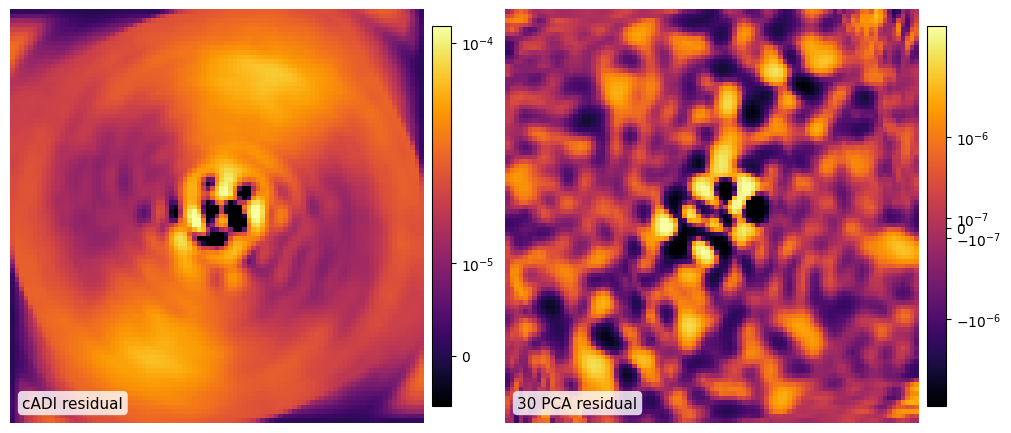

In [ ]:
res_cadi = load_residual(CADI_DIR, "0000")
res_pca = load_residual(PCA_DIR, "0000")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
for ax, img, label in zip(
    axes, [res_cadi, res_pca], ["cADI residual", f"{N_PCA} PCA residual"]
):
    im = ax.imshow(
        img, origin="lower", cmap=CMAP, norm=symlog_norm(img)
    )  # own symlog range per image
    ax.set_axis_off()
    add_corner_label(ax, label)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cbar.ax.tick_params(labelsize=9)

fig.savefig(
    SAVE_APPLEFY / f"residual_0000_cADI_vs_PCA{N_PCA:03d}.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 5.2 Movie of the fake-planet injections, PCA residuals

All residual frames of the PCA folder, in injection order (`0000` first, then the planets).

In [ ]:
cube_pca, frame_ids = load_residual_cube(PCA_DIR)
seps_fwhm, planet_xy, fwhm_px = load_planet_configs(CONFIGS, frame_ids)
print(
    f"{cube_pca.shape[0]} frames, first/last: {frame_ids[0]} / {frame_ids[-1]}, FWHM = {fwhm_px:.2f} px"
)

labels = [
    (
        f" {N_PCA} PCA \nSeparation: {seps_fwhm[fid]:.0f}FWHM"
        if np.isfinite(seps_fwhm[fid])
        else f" {N_PCA} PCA \nSeparation: no planet"
    )
    for fid in frame_ids
]
xy = [planet_xy[fid] for fid in frame_ids]

# 1) full residual, symlog colour scale, dashed circle (1 FWHM radius) around the injected planet
out_mp4 = SAVE_APPLEFY / f"fake_planets_PCA{N_PCA:03d}_residuals.mp4"
norm_mov = cube_to_video(
    cube_pca, labels, out_mp4, planet_xy=xy, circle_radius=fwhm_px, fps=5
)
print(
    f"saved {out_mp4}  (range {norm_mov.vmin:.3g} .. {norm_mov.vmax:.3g} ADU, "
    f"linear within +-{norm_mov.linthresh:.3g})"
)

# 2) planet signal only: residual minus the planet-free residual (frame 0000)
cube_planet = cube_pca - cube_pca[frame_ids.index("0000")]
out_mp4_planet = SAVE_APPLEFY / f"fake_planets_PCA{N_PCA:03d}_planet_only.mp4"
norm_planet = cube_to_video(
    cube_planet,
    labels,
    out_mp4_planet,
    planet_xy=xy,
    circle_radius=fwhm_px,
    fps=5,
    norm=symlog_norm(cube_planet, pmin=0.1, pmax=99.99),
)
print(
    f"saved {out_mp4_planet}  (range {norm_planet.vmin:.3g} .. {norm_planet.vmax:.3g} ADU)"
)

# 6. Comparison movies (log scale)

* 6.1: open loop (bench), integrator and predictor for the 24 key run, first 50 frames side by side, one shared log colour scale and a single colorbar.
* 6.2: raw camera frames 100 to 200 of the key 1 predictor run (multi-page .tif), log scale, no colorbar, no text.

In [ ]:
SAVE_COMPARE = Path("/home/aosimul/noah/notebooks/results/comparison_movies")
SAVE_COMPARE.mkdir(parents=True, exist_ok=True)


def log_norm(cubes, pmin=1, pmax=99.9):
    """One LogNorm shared by all the given arrays (percentile range over everything)."""
    allv = np.concatenate([np.asarray(c, dtype=float).ravel() for c in cubes])
    allv = allv[np.isfinite(allv) & (allv > 0)]
    vmin, vmax = np.percentile(allv, [pmin, pmax])
    return LogNorm(vmin=vmin, vmax=vmax)


def panels_to_video(
    cubes,
    out_path,
    labels=None,
    norm=None,
    colorbar=True,
    fps=10,
    cmap=CMAP,
    panel_size=3.6,
    dpi=120,
):
    """Side-by-side movie of several (n, y, x) cubes, same frame index in every panel, one
    colour normalisation for all panels. Optional corner labels and a single colorbar.
    """
    n_frames = min(len(c) for c in cubes)
    if norm is None:
        norm = log_norm(cubes)
    fig, axes = plt.subplots(
        1,
        len(cubes),
        figsize=(panel_size * len(cubes), panel_size),
        dpi=dpi,
        constrained_layout=colorbar,
        squeeze=False,
    )
    ims = []
    for k, (ax, cube) in enumerate(zip(axes[0], cubes)):
        ims.append(ax.imshow(cube[0], origin="lower", cmap=cmap, norm=norm))
        ax.set_axis_off()
        if labels is not None:
            add_corner_label(ax, labels[k])
    if colorbar:
        cbar = fig.colorbar(
            ims[-1], ax=axes[0].tolist(), fraction=0.046 / len(cubes), pad=0.02
        )
        cbar.ax.tick_params(labelsize=9)
    else:
        fig.subplots_adjust(0, 0, 1, 1, wspace=0.02)
    with imageio.get_writer(
        out_path, fps=fps, codec="libx264", quality=8, macro_block_size=1
    ) as writer:
        for i in range(n_frames):
            for im, cube in zip(ims, cubes):
                im.set_data(cube[i])
            fig.canvas.draw()
            writer.append_data(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    return norm

## 6.1 OL vs int vs pred, 24 key, first 50 frames

In [ ]:
N_FRAMES = 50
run24 = dict(ro=7, ws=20, key=24, count="1-4")
cubes_24 = [
    load_stack(RUNS_BENCH, algo="OL", **run24)[:N_FRAMES],
    load_stack(LONG_RUN_FOCUS, algo="int", **run24)[:N_FRAMES],
    load_stack(LONG_RUN_FOCUS, algo="pred", **run24)[:N_FRAMES],
]

out_24 = SAVE_COMPARE / "OL_int_pred_7ro_20ws_24key_first50_log.mp4"
norm_24 = panels_to_video(cubes_24, out_24, labels=["OL", "int", "pred"], fps=10)
print(f"saved {out_24}  (log range {norm_24.vmin:.3g} .. {norm_24.vmax:.3g})")

## 6.2 Raw camera frames 100 to 200, key 1 predictor run

In [ ]:
RAW_TIF = RAW_TIF_DIR / "pred_7ro_20ws_key1_coro_2026-10-10T14-50-04.066_0.tif"
raw_frames = tiff.imread(RAW_TIF, key=slice(100, 200)).astype(
    float
)  # (100, 200, 200), uint16 camera ADU
print(raw_frames.shape)

out_raw = SAVE_COMPARE / "raw_pred_7ro_20ws_key1_frames100-200_log.mp4"
norm_raw = panels_to_video(
    [raw_frames], out_raw, labels=None, colorbar=False, fps=10, panel_size=4
)
print(f"saved {out_raw}  (log range {norm_raw.vmin:.3g} .. {norm_raw.vmax:.3g})")